# El espectro de la D1 con los datos de Steck

Este notebook calcula el espectro de absorción de la línea D1 del rubidio natural (795 nm). La idea es simple: con los datos de Steck sabemos dónde está cada línea y cuánto absorbe. Ponemos una gaussiana en cada línea, por el ensanchamiento Doppler, y las sumamos. Al final ajustamos ese espectro a los datos medidos para obtener la fracción de ⁸⁷Rb de la celda.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

kB = 1.380649e-23           # J/K
c = 2.99792458e8            # m/s
u = 1.66053907e-27          # kg
NU0 = 377107463.38          # MHz, frecuencia de la D1
MASA = {"87": 86.909 * u, "85": 84.912 * u}
COLOR = {"87": "#c0392b", "85": "#2471a3"}

nu = np.linspace(-5500, 6500, 1201)  # MHz

## 1. Dónde está cada línea

El rubidio natural tiene dos isótopos, ⁸⁵Rb y ⁸⁷Rb. En cada uno, el estado fundamental (5S₁/₂) tiene dos niveles hiperfinos $F$, y el excitado (5P₁/₂) otros dos, $F'$. Cada $F$ puede saltar a cada $F'$, así que hay cuatro líneas por isótopo y ocho en total. Con los datos de Steck, cada línea queda en esta frecuencia y con esta intensidad:

| Isótopo | $F \to F'$ | Frecuencia [MHz] | Intensidad |
|:---:|:---:|---:|---:|
| ⁸⁷Rb | 2 → 1 | −3072,1 | 0,3125 |
| ⁸⁷Rb | 2 → 2 | −2257,6 | 0,3125 |
| ⁸⁵Rb | 3 → 2 | −1553,5 | 0,3241 |
| ⁸⁵Rb | 3 → 3 | −1191,9 | 0,2593 |
| ⁸⁵Rb | 2 → 2 | 1482,2 | 0,0926 |
| ⁸⁵Rb | 2 → 3 | 1843,8 | 0,3241 |
| ⁸⁷Rb | 1 → 1 | 3762,6 | 0,0625 |
| ⁸⁷Rb | 1 → 2 | 4577,1 | 0,3125 |

La frecuencia de cada línea es la diferencia de energía entre sus dos niveles, más el corrimiento isotópico; el cero es el centro de la D1 del ⁸⁷Rb. La intensidad es el producto de dos números: la fracción de átomos que está en el nivel $F$, $(2F+1)/[2(2I+1)]$ con $I$ el espín nuclear, y la intensidad relativa del salto $F\to F'$. Las energías, los espines y las intensidades relativas son de Steck. Así, las cuatro intensidades de cada isótopo suman 1.

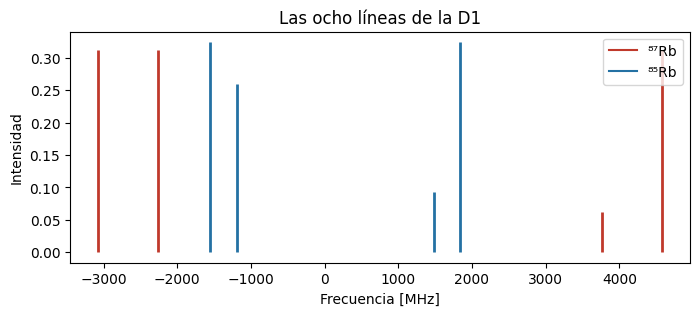

In [2]:
# (isótopo, frecuencia [MHz], intensidad)
LINEAS = [
    ("87", -3072.1, 0.3125),
    ("87", -2257.6, 0.3125),
    ("85", -1553.5, 0.3241),
    ("85", -1191.9, 0.2593),
    ("85",  1482.2, 0.0926),
    ("85",  1843.8, 0.3241),
    ("87",  3762.6, 0.0625),
    ("87",  4577.1, 0.3125),
]

fig, ax = plt.subplots(figsize=(8, 3))
for iso, frecuencia, intensidad in LINEAS:
    ax.vlines(frecuencia, 0, intensidad, color=COLOR[iso], lw=2)
ax.plot([], [], color=COLOR["87"], label="⁸⁷Rb")
ax.plot([], [], color=COLOR["85"], label="⁸⁵Rb")
ax.set(xlabel="Frecuencia [MHz]", ylabel="Intensidad", title="Las ocho líneas de la D1")
ax.legend()
plt.show()

## 2. Una gaussiana en cada línea, y las sumamos

Los átomos del vapor se mueven, y por efecto Doppler cada uno absorbe a una frecuencia un poco distinta. Sus velocidades a lo largo del haz siguen la distribución de Maxwell, que es una gaussiana. Por eso cada línea se vuelve una gaussiana:

- su centro es la frecuencia de la línea;
- su desvío es $\sigma = \dfrac{\nu}{c}\sqrt{\dfrac{k_B T}{m}}$, donde $m$ es la masa de un átomo (unas 85 u). A 295 K da $\sigma \approx 214$ MHz.

Sin Doppler, cada línea ya tendría un ancho natural de unos 6 MHz. Frente a 214 MHz es despreciable, así que tomamos cada línea como una gaussiana pura.

El espectro es la suma de las ocho gaussianas, cada una multiplicada por la intensidad de su línea:

$$A(\nu) = \sum_{\text{líneas}} \text{intensidad}\cdot G(\nu;\ \text{centrada en la línea},\ \sigma).$$

Cada gaussiana $G$ tiene área 1. En el gráfico ya multiplicamos cada línea por la proporción de su isótopo en el rubidio natural; eso lo explicamos en la sección 3.

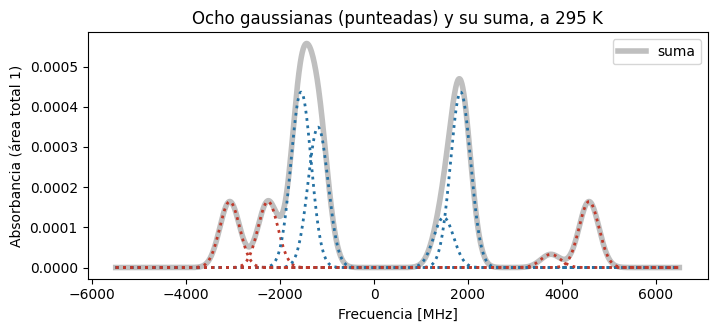

In [3]:
T = 295  # K
suma = 0
fig, ax = plt.subplots(figsize=(8, 3.2))
for iso, frecuencia, intensidad in LINEAS:
    p = 0.2783 if iso == "87" else 0.7217
    sigma = NU0 / c * np.sqrt(kB * T / MASA[iso])
    G = np.exp(-(nu - frecuencia)**2 / (2 * sigma**2)) / (sigma * np.sqrt(2 * np.pi))
    ax.plot(nu, p * intensidad * G, ":", color=COLOR[iso], lw=2)
    suma = suma + p * intensidad * G
ax.plot(nu, suma, color="0.75", lw=4, zorder=0, label="suma")
ax.set(xlabel="Frecuencia [MHz]", ylabel="Absorbancia (área total 1)",
       title="Ocho gaussianas (punteadas) y su suma, a 295 K")
ax.legend()
plt.show()

Las dos líneas de cada grupo del ⁸⁵Rb están a 362 MHz, así que se funden en un solo pico. Las del ⁸⁷Rb están a 815 MHz y todavía se distinguen. El espectro que medimos es más ancho, y por eso en él vemos solo cuatro pozos.

## 3. La fracción de ⁸⁷Rb

Las intensidades de la tabla son relativas dentro de cada isótopo: las cuatro de cada uno suman 1. Para juntar los dos isótopos falta saber cuántos átomos hay de cada uno. Si una fracción $p$ de los átomos es de ⁸⁷Rb, multiplicamos las intensidades del ⁸⁷Rb por $p$ y las del ⁸⁵Rb por $1-p$:

$$A(\nu) = \sum_{\text{líneas}} p_\text{isótopo}\cdot\text{intensidad}\cdot G, \qquad p_{87} = p,\quad p_{85} = 1-p.$$

Esto supone que un átomo de cada isótopo absorbe lo mismo en total, lo que vale para la D1.

Como las intensidades de cada isótopo suman 1, el total sigue sumando 1 para cualquier $p$. Así, cambiar $p$ no cambia el área: solo pasa absorción de los grupos del medio (⁸⁵Rb) a los de los costados (⁸⁷Rb). Por eso el ajuste puede medir $p$: compara la altura de los grupos de los costados con la de los del medio.

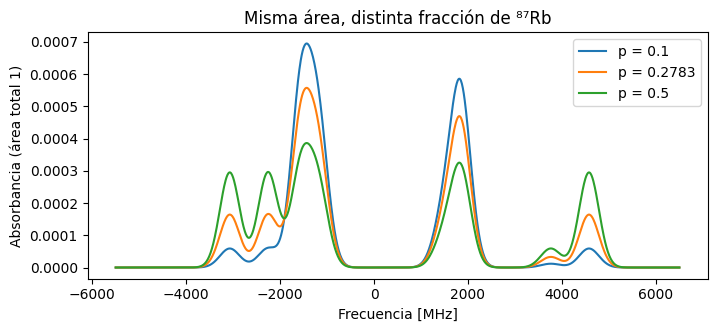

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.2))
for p87 in [0.10, 0.2783, 0.50]:
    suma = 0
    for iso, frecuencia, intensidad in LINEAS:
        p = p87 if iso == "87" else 1 - p87
        sigma = NU0 / c * np.sqrt(kB * T / MASA[iso])
        G = np.exp(-(nu - frecuencia)**2 / (2 * sigma**2)) / (sigma * np.sqrt(2 * np.pi))
        suma = suma + p * intensidad * G
    ax.plot(nu, suma, label=f"p = {p87}")
ax.set(xlabel="Frecuencia [MHz]", ylabel="Absorbancia (área total 1)",
       title="Misma área, distinta fracción de ⁸⁷Rb")
ax.legend()
plt.show()

## 4. El factor de área

La suma de la sección 3 siempre tiene área 1: cada gaussiana tiene área 1, las intensidades de cada isótopo suman 1 y las dos fracciones también. Esa suma da la **forma** del espectro, es decir, dónde están las líneas y cómo se reparten la absorción. No da su tamaño, porque las intensidades de Steck son relativas: dicen que una línea absorbe cinco veces más que otra, no cuánto absorbe cada una.

El tamaño depende de cuántos átomos cruza el haz, es decir, de la densidad $n$ por el largo $L$ de la celda. Por eso multiplicamos todo por un factor, el área bajo el espectro:

$$A(\nu) = \text{area}\sum_{\text{líneas}} p_\text{isótopo}\cdot\text{intensidad}\cdot G, \qquad \text{area} = \int A\,d\nu = n\,L\,\pi r_e c f.$$

En la fórmula del área, $r_e$ es el radio clásico del electrón y $f = 0{,}342$ la fuerza de oscilador de la D1 (ver el apéndice del informe). Como no conocemos bien $n$ ni $L$, en el ajuste dejamos el área libre.

Usamos el área y no la altura porque el ensanchamiento reparte la absorción en más frecuencias, pero no cambia su total. Si ensanchamos una gaussiana sin cambiar su área, el pico baja. Así, el área fija el tamaño y $T$ el ancho, sin pisarse en el ajuste. Además, el área ajustada mide $nL$ aunque las líneas sean más anchas que el Doppler: por eso el informe puede sacar la temperatura de la celda del área.

Por último, agregamos un corrimiento de todo el espectro, `centro`, para absorber un error en el cero del eje de frecuencia.

## 5. La función

In [5]:
def steck(nu, fraccion87, T, area, centro):
    A = 0
    for iso, frecuencia, intensidad in LINEAS:
        if iso == "87":
            p = fraccion87
        else:
            p = 1 - fraccion87
        sigma = NU0 / c * np.sqrt(kB * T / MASA[iso])
        G = np.exp(-(nu - frecuencia - centro)**2 / (2 * sigma**2)) / (sigma * np.sqrt(2 * np.pi))
        A = A + p * intensidad * G
    return area * A

## 6. Ajuste a los datos: la fracción de ⁸⁷Rb

Usamos los registros sin imanes del día 2, que están en `data/dia2/`. [barridos.py](barridos.py) hace el procesamiento de la sección Análisis de datos del informe: corta cada registro en semibarridos, calcula su absorbancia con una recta como fondo, ajustada lejos de los pozos, pasa cada semibarrido a frecuencia con los dos pozos del ⁸⁵Rb y promedia todos con un promedio gaussiano de 100 MHz.

In [6]:
from pathlib import Path
from barridos import semibarridos, calibrar, promedio, NU

lista = []
for archivo in sorted(Path("../data/dia2").glob("d2-*_barrido_sin-imanes-1hz.csv")):
    lista = lista + semibarridos(archivo)
calibrar(lista)

ventana = np.abs(NU) < 5500
x = NU[ventana]
A_medida = promedio(lista)[ventana]
print(f"{len(lista)} semibarridos de {len({s['archivo'] for s in lista})} archivos")

31 semibarridos de 9 archivos


El ajuste deja libres los cuatro parámetros de `steck`: la fracción, $T$, el área y el corrimiento. Como son todos los argumentos que vienen después de `nu`, alcanza con pasarle `steck` a `curve_fit` y darle valores iniciales.

fraccion87 = 0.277,  T = 869 K (sigma = 367 MHz),  area = 392 MHz,  centro = 27 MHz


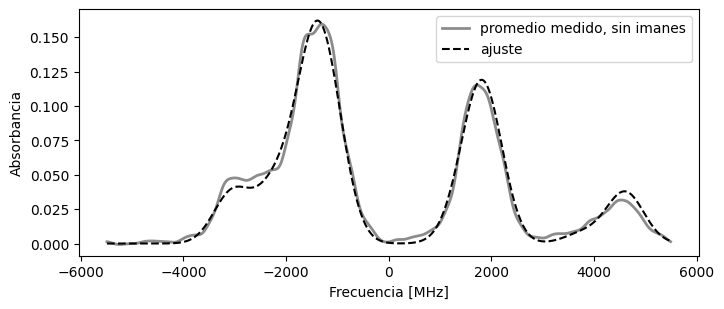

In [7]:
p, _ = curve_fit(steck, x, A_medida, p0=[0.28, 800, 400, 0])
fraccion87, T_ajuste, area, centro = p
sigma = NU0 / c * np.sqrt(kB * T_ajuste / MASA["85"])
print(f"fraccion87 = {fraccion87:.3f},  T = {T_ajuste:.0f} K (sigma = {sigma:.0f} MHz),  "
      f"area = {area:.0f} MHz,  centro = {centro:.0f} MHz")

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(x, A_medida, color="0.55", lw=2, label="promedio medido, sin imanes")
ax.plot(x, steck(x, *p), "--", color="k", label="ajuste")
ax.set(xlabel="Frecuencia [MHz]", ylabel="Absorbancia")
ax.legend()
plt.show()

La $T$ del ajuste no es la temperatura de la celda: es el ancho de los pozos medido, expresado como temperatura. Los pozos son más anchos que el Doppler a 295 K por el jitter del láser y por nuestro promedio (ver el informe).

Para el error repetimos el ajuste dejando afuera, cada vez, uno de los archivos (*jackknife*). Usamos el archivo y no el semibarrido porque los semibarridos de un mismo archivo comparten la deriva del láser.

In [8]:
nombres = sorted({s["archivo"] for s in lista})
fracciones = []
for nombre in nombres:
    resto = [s for s in lista if s["archivo"] != nombre]
    p_resto, _ = curve_fit(steck, x, promedio(resto)[ventana], p0=p)
    fracciones.append(p_resto[0])
fracciones = np.array(fracciones)
n = len(fracciones)
error = np.sqrt((n - 1) / n * np.sum((fracciones - fracciones.mean())**2))
print(f"fracción de 87Rb = ({100*fraccion87:.1f} ± {100*error:.1f}) %   (natural: 27.83 %)")

fracción de 87Rb = (27.7 ± 0.6) %   (natural: 27.83 %)


Fuente de los datos atómicos: D. A. Steck, [*Rubidium 85 D Line Data* y *Rubidium 87 D Line Data*](https://steck.us/alkalidata/).